In [3]:
#Lab1: Understanding Deep Learning and Neural Network
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/smartcart_dataset.csv')

print("Shape:", df.shape)
print(df["category"].value_counts())
df.head()

Shape: (1200, 6)
category
Apparel        400
Electronics    400
Grocery        400
Name: count, dtype: int64


,price,weight_kg,rating,discount_pct,description_length,category
0,438.29,3.413,4.1,57.5,47,Apparel
1,719.57,6.111,3.5,46.5,45,Apparel
2,1202.48,9.337,4.1,23.7,109,Electronics
3,316.98,2.752,4.4,21.9,20,Grocery
4,2037.38,6.407,3.6,14.1,93,Electronics


<Axes: xlabel='price', ylabel='weight_kg'>

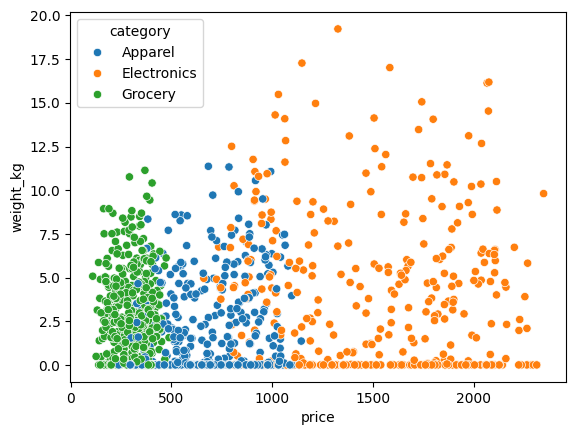

In [5]:
sns.scatterplot(data=df, x='price', y='weight_kg', hue='category')

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

FEATURES = ['price', 'weight_kg', 'rating', 'discount_pct', 'description_length']
TARGET = 'category'

X = df[FEATURES]
y_raw = df[TARGET]
le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_
print(dict(zip(range(len(class_names)), class_names)))

{0: 'Apparel', 1: 'Electronics', 2: 'Grocery'}


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train.shape, X_test.shape

((960, 5), (240, 5))

In [8]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

perceptron = Sequential()
perceptron.add(Dense(3, activation='softmax', input_dim=X_train.shape[1]))

perceptron.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
perceptron.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
history_p = perceptron.fit(X_train, y_train, epochs=100,
                            validation_split=0.2, verbose=0)

In [10]:
weights, bias = perceptron.layers[0].get_weights()
print('weights:\n', weights)
print('bias:\n', bias)

weights:
 [[-0.3469833   1.543236   -1.2374562 ]
 [ 0.13000095  0.5961038   0.5777502 ]
 [ 0.02988013  0.70028204  0.09532148]
 [ 0.79554176 -0.32679704 -1.1420252 ]
 [-0.21913107  0.89588404 -1.3856369 ]]
bias:
 [ 0.5304617  -0.01249974 -0.6234865 ]


In [11]:
perceptron_loss, perceptron_acc = perceptron.evaluate(X_test, y_test, verbose=0)
print(f'Perceptron test accuracy: {perceptron_acc:.3f}')

Perceptron test accuracy: 0.896


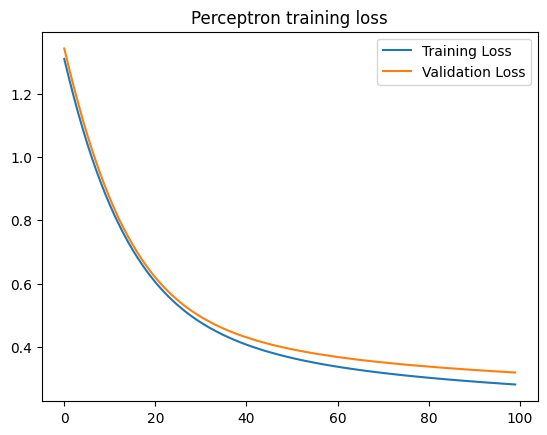

In [12]:
plt.plot(history_p.history['loss'], label='Training Loss')
plt.plot(history_p.history['val_loss'], label='Validation Loss')
plt.title('Perceptron training loss')
plt.legend()
plt.show()

In [13]:
ann = Sequential()
ann.add(Dense(32, activation='relu', input_dim=X_train.shape[1]))
ann.add(Dense(16, activation='relu'))
ann.add(Dense(3, activation='softmax'))

ann.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
ann.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
history_ann = ann.fit(X_train, y_train, epochs=100,
                       validation_split=0.2, verbose=0)
ann_loss, ann_acc = ann.evaluate(X_test, y_test, verbose=0)
print(f'ANN test accuracy: {ann_acc:.3f}')

ANN test accuracy: 0.942


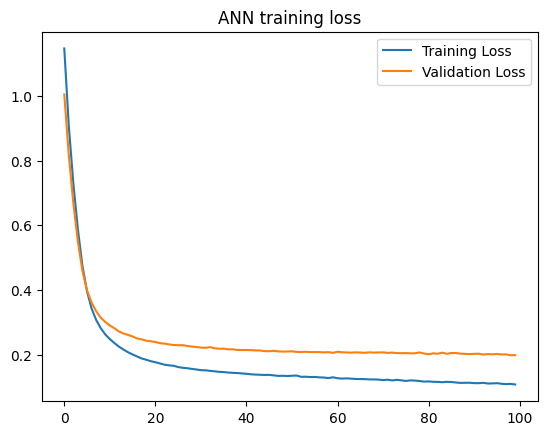

In [15]:
plt.plot(history_ann.history['loss'],
label='Training Loss')
plt.plot(history_ann.history['val_loss'],
label='Validation Loss')
plt.title('ANN training loss')
plt.legend()
plt.show()

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train, y_train)
y_pred_logreg = log_reg.predict(X_test)
logreg_acc = accuracy_score(y_test, y_pred_logreg)

print(f"Logistic Regression test accuracy: {logreg_acc:.3f}\n")
print(classification_report(y_test, y_pred_logreg, target_names=class_names))

Logistic Regression test accuracy: 0.925

              precision    recall  f1-score   support

     Apparel       0.92      0.85      0.88        80
 Electronics       0.94      0.95      0.94        80
     Grocery       0.92      0.97      0.95        80

    accuracy                           0.93       240
   macro avg       0.92      0.92      0.92       240
weighted avg       0.92      0.93      0.92       240



8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


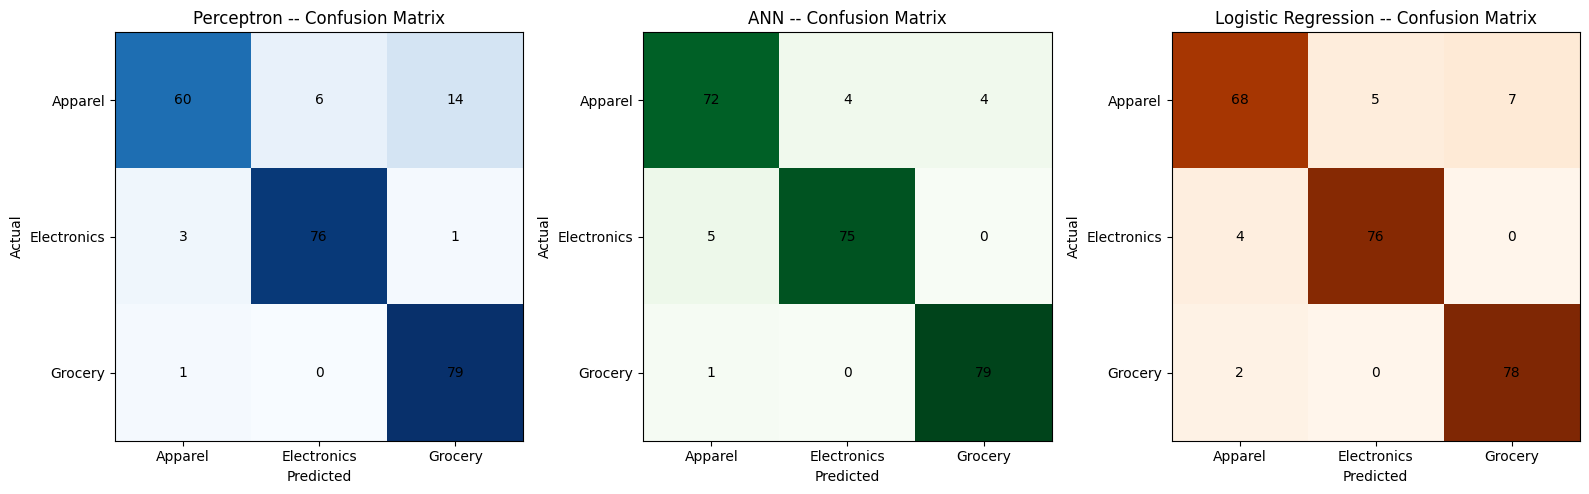

In [22]:
from sklearn.metrics import confusion_matrix

# Generate predicted class indices from model probabilities
y_pred_perceptron = perceptron.predict(X_test).argmax(axis=1)
y_pred_ann = ann.predict(X_test).argmax(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, y_pred, title, cmap in zip(
        axes,
        [y_pred_perceptron, y_pred_ann, y_pred_logreg],
        ['Perceptron -- Confusion Matrix', 'ANN -- Confusion Matrix',
        'Logistic Regression -- Confusion Matrix'],
        ['Blues', 'Greens', 'Oranges']):
    cm = confusion_matrix(y_test, y_pred)
    im = ax.imshow(cm, cmap=cmap)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(title)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

In [23]:
comparison = pd.DataFrame({
    'Model': ['Perceptron (Keras)', 'Logistic Regression (sklearn)',
              'ANN (Keras)'],
    'Test Accuracy': [perceptron_acc,logreg_acc ,ann_acc ]})
comparison

,Model,Test Accuracy
0,Perceptron (Keras),0.895833
1,Logistic Regression (sklearn),0.925000
2,ANN (Keras),0.941667
